# Origraphi — Online Study (Prolific): Analysis

Compares **unfolded** (standard BioFabric) and **folded** (Origraphi edge folding) between subjects.

Tasks (3 trials each):

- **T1 – Adjacency** (`task1`): select the nodes connected to the highlighted node.
- **T2 – Common neighbors** (`task2`): select the common neighbors of two highlighted nodes.
- **T3 – Size** (`task3`): estimate the number of edges in the graph.

Hypotheses and tests:

- **H1** Folding preserves task accuracy → TOST equivalence test on overall accuracy, margin ±5 points
- **H2** Folding does not meaningfully affect perceived workload → TOST on overall RTLX, margin ±10 points
- **H3** Folding shortens response times on T2 → one-sided Mann-Whitney U on T2 response times

**TOST** (two one-sided tests) is an equivalence test. It tests whether the difference between the
conditions is both above −margin and below +margin. If both one-sided tests are significant, the
conditions are equivalent; this is the same as the 90% CI of the difference lying within ±margin.

Every test uses one value per participant (mean of the 3 trials per task; median for response time);
`overall` is the mean of a participant's three tasks. Differences are **folded − unfolded**.
The first cell loads the libraries and sets the data paths, margins and exclusion thresholds.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

import biofab_stats as bs

warnings.filterwarnings("ignore", category=RuntimeWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 2)
COND_PALETTE = {"folded": "#4C72B0", "unfolded": "#DD8452"}

# every figure is also saved as an SVG (text stays editable) in FIG_DIR
FIG_DIR = "figures"
plt.rcParams["svg.fonttype"] = "none"


def show(name):
    os.makedirs(FIG_DIR, exist_ok=True)
    plt.savefig(f"{FIG_DIR}/{name}.svg", bbox_inches="tight")
    plt.show()

# ---- settings (fixed before looking at the data) ----
DATA_PATH = "data/biofabric-study_prolific_tidy.csv"
EDGE_TRUTH_PATH = "estimation_graph_truth.csv"
ALPHA = 0.05
MARGINS = {"accuracy": 5.0, "rtlx": 10.0}   # equivalence margins: accuracy points, RTLX points

# exclusions
MIN_COMPLETED = 27              # full session required
ATTN_MAX_FAILS = 0              # any failed attention check excludes
CLICKTHROUGH_MEDIAN_MS = 8000   # median trial time below this = clicking through
MIN_TRIAL_RT_MS = 3000          # trial faster than this is dropped
RT_MAD_K = 3.0                  # trial slower than task median + 3 MAD (log scale): RT dropped
MANUAL_EXCLUSIONS = {}          # {participantId: "reason"}

## Data and exclusions

Loads the reVISit export and applies the exclusion rules from the first cell. Participants with an
incomplete session, a failed attention check or a click-through pattern are removed. Single trials
that are implausibly fast are dropped; implausibly slow ones lose their response time but keep their
accuracy. The table shows how many participants remain per condition.

In [2]:
df, trials_raw, tlx_raw = bs.load_trials(DATA_PATH, EDGE_TRUTH_PATH, rt_col="cleanedDuration")
trials, tlx, participants, flagged = bs.apply_exclusions(
    df, trials_raw, tlx_raw, manual=MANUAL_EXCLUSIONS, min_completed=MIN_COMPLETED,
    attn_max_fails=ATTN_MAX_FAILS, clickthrough_median_ms=CLICKTHROUGH_MEDIAN_MS,
    min_rt_ms=MIN_TRIAL_RT_MS, mad_k=RT_MAD_K)
dvs = bs.build_dvs(trials, tlx, rt_agg="median")

flow = participants.assign(status=participants["exclusion"].replace("", "analysed"))
display(pd.crosstab(flow["status"], flow["condition"], margins=True, margins_name="total"))
print(f"Trials with RT removed: {flagged['too_slow'].sum()} too slow, {flagged['too_fast'].sum()} too fast "
      f"(of {len(trials)})")

condition,default,folded,unfolded,total
status,,,,
analysed,0,52,52,104
failed attention check(s),0,2,1,3
incomplete session,5,62,84,151
total,5,116,137,258


Trials with RT removed: 16 too slow, 0 too fast (of 936)


## Exploration

Shows the per-participant values for accuracy, RTLX and response time, per task and pooled
(`overall`), to check their distributions before testing. Box = middle 50 % of participants,
line = median, dots = participants.

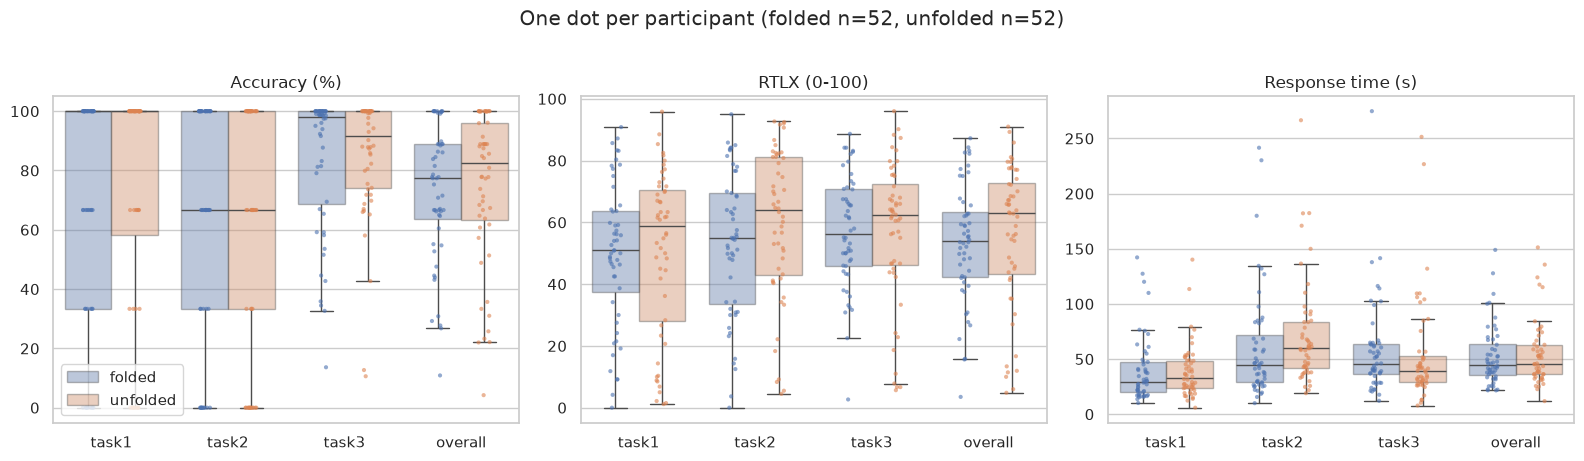

In [3]:
N = dvs[dvs["dv"] == "accuracy"].groupby("condition")["participantId"].nunique()
N_TEXT = f"folded n={N['folded']}, unfolded n={N['unfolded']}"
TITLES = {"accuracy": "Accuracy (%)", "rtlx": "RTLX (0-100)", "rt": "Response time (s)"}

plot_df = dvs.assign(value=np.where(dvs["dv"] == "rt", dvs["value"] / 1000, dvs["value"]))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, dv in zip(axes, ["accuracy", "rtlx", "rt"]):
    d = plot_df[plot_df["dv"] == dv]
    sns.boxplot(data=d, x="task", y="value", hue="condition", palette=COND_PALETTE, hue_order=list(COND_PALETTE), order=bs.TASK_ORDER,
                showfliers=False, boxprops={"alpha": .4}, ax=ax, legend=ax is axes[0])
    sns.stripplot(data=d, x="task", y="value", hue="condition", palette=COND_PALETTE, hue_order=list(COND_PALETTE), order=bs.TASK_ORDER,
                  dodge=True, legend=False, size=3, alpha=.6, ax=ax)
    ax.set(title=TITLES[dv], xlabel="", ylabel="")
axes[0].legend(title=None, loc="lower left")
fig.suptitle(f"One dot per participant ({N_TEXT})", y=1.02)
plt.tight_layout()
show("exploration")

Summary statistics (n, mean, SD, median) per measure, task and condition.

In [4]:
summary = (plot_df.groupby(["dv", "task", "condition"])["value"]
           .agg(n="count", mean="mean", sd="std", median="median")
           .unstack("condition").reindex(bs.TASK_ORDER, level="task"))
summary.rename(index=TITLES, level="dv")

n            mean              sd           \
condition                 folded unfolded folded unfolded folded unfolded   
dv                task                                                      
Accuracy (%)      task1       52       52  69.23    73.08  38.97    39.07   
                  task2       52       52  65.38    64.74  38.47    40.91   
                  task3       52       52  83.71    84.94  23.25    20.46   
                  overall     52       52  72.78    74.25  22.93    25.73   
Response time (s) task1       52       52  39.79    38.86  30.02    24.45   
                  task2       52       52  60.48    71.85  49.85    47.88   
                  task3       52       52  57.79    53.63  42.73    47.02   
                  overall     52       52  52.69    54.78  27.35    29.39   
RTLX (0-100)      task1       52       52  49.95    50.67  23.18    26.90   
                  task2       52       52  53.03    59.56  23.47    24.45   
                  task3       52       52  57.00    56.90  18.04    23.33   
                  overall     52       52  53.33    55.71  19.04    23.35   

                           median           
condition                  folded unfolded  
dv                task                      
Accuracy (%)      task1    100.00   100.00  
                  task2     66.67    66.67  
                  task3     98.02    91.62  
                  overall   77.37    82.54  
Response time (s) task1     29.59    32.91  
                  task2     44.63    59.79  
                  task3     45.96    39.47  
                  overall   44.69    45.78  
RTLX (0-100)      task1     50.92    58.67  
                  task2     54.83    63.92  
                  task3     56.25    62.25  
                  overall   53.97    62.89

## Hypothesis tests

Runs all tests (implemented in `biofab_stats.py`) and defines the two-panel figure used below:
on the left each condition's value with a 95% CI, on the right the difference folded − unfolded with
its CI.

In [5]:
results = bs.run_hypotheses(dvs, MARGINS, alpha=ALPHA)


def ci_plot(rows, est, lo, hi, title, xlabel, margin=None, left="", right="", dv=None, value_label="",
            center="mean", scale=1.0, ci_label="90% CI", name="ci_plot"):
    # left (if dv given): each condition's mean with 95% CI; right: difference with CI and margin band
    rows = rows.set_index("task").loc[bs.TASK_ORDER[::-1]]
    y = np.arange(len(rows))
    if dv:
        fig, (ax0, ax) = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True, gridspec_kw={"width_ratios": [1, 1.15]})
        d = dvs[dvs["dv"] == dv]
        for k, (cond, color) in enumerate(COND_PALETTE.items()):
            g = d[d["condition"] == cond].groupby("task")["value"]
            if center == "mean":
                m, half = g.mean(), g.sem() * stats.t.ppf(.975, g.count() - 1)
                m_lo, m_hi = m - half, m + half
            else:  # median with bootstrap 95% CI
                rng = np.random.default_rng(1)
                m = g.median()
                boots = g.apply(lambda v: np.percentile(
                    [np.median(rng.choice(v.to_numpy(), len(v))) for _ in range(2000)], [2.5, 97.5]))
                m_lo, m_hi = boots.map(lambda b: b[0]), boots.map(lambda b: b[1])
            m, m_lo, m_hi = m / scale, m_lo / scale, m_hi / scale
            off = .12 if k == 0 else -.12
            ax0.hlines(y + off, m_lo[rows.index], m_hi[rows.index], color=color, lw=2.5)
            ax0.scatter(m[rows.index], y + off, color=color, s=40, zorder=3, label=cond)
        ax0.set(title=f"{center.capitalize()} per condition (95% CI)", xlabel=value_label)
        ax0.set_yticks(y, rows.index)
        ax0.legend(loc="lower left", fontsize=8)
    else:
        fig, ax = plt.subplots(figsize=(7, 3.2))
    if margin:
        ax.axvspan(-margin, margin, color="#55A868", alpha=.15, label=f"equivalence margin ±{margin:g}")
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
    ax.axvline(0, color="black", lw=1, ls="--")
    ax.hlines(y, rows[lo], rows[hi], color="#333333", lw=2.5)
    ax.scatter(rows[est], y, color="#333333", zorder=3, s=40)
    ax.set_yticks(y, rows.index)
    lim = max(abs(v) for v in ax.get_xlim())
    ax.set_xlim(-lim, lim)  # symmetric, so 0 sits in the middle
    for x, text, ha in [(-lim, f"← {left}", "left"), (lim, f"{right} →", "right")]:
        ax.text(x, 1.01, text, transform=ax.get_xaxis_transform(), ha=ha, va="bottom", fontsize=8, color="#555555")
    ax.set_title(f"Difference ({ci_label})", pad=16)
    ax.set_xlabel(xlabel)
    fig.suptitle(f"{title}  ({N_TEXT})", y=1.02)
    plt.tight_layout()
    show(name)

### H1 — Accuracy

TOST equivalence test on overall accuracy. The conditions are equivalent if the whole 90% CI of the
difference lies within ±5 points (the green band).
Also prints both one-sided t-tests, the ordinary difference test, and the smallest margin for which
the conditions would count as equivalent.


Overall: diff = -1.5 pts, 90% CI [-9.4, +6.5], TOST p = 0.231 -> inconclusive
  one-sided tests: t(100.7) = 0.74, p = 0.231 (above -margin); t(100.7) = -1.36, p = 0.089 (below +margin)
  difference test: Welch p = 0.758, Hedges' g = -0.06
  equivalent for any margin of ±9.4 points or wider


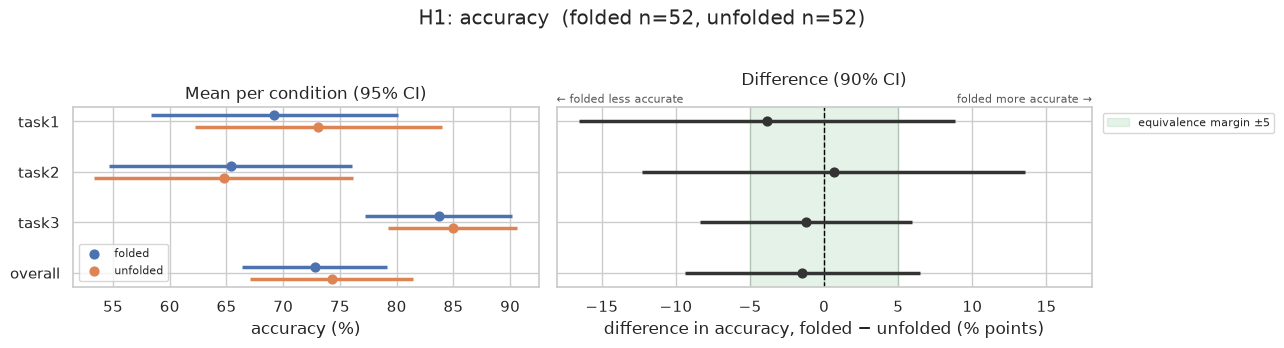

In [6]:
h1 = results[results["dv"] == "accuracy"]
r = h1[h1["role"] == "primary"].iloc[0]
print(f"Overall: diff = {r['diff']:+.1f} pts, 90% CI [{r['ci90_lo']:+.1f}, {r['ci90_hi']:+.1f}], "
      f"TOST p = {r['p']:.3f} -> {r['verdict']}")
print(f"  one-sided tests: t({r['df_tost']:.1f}) = {r['t_lower']:.2f}, p = {r['p_lower']:.3f} (above -margin); "
      f"t({r['df_tost']:.1f}) = {r['t_upper']:.2f}, p = {r['p_upper']:.3f} (below +margin)")
print(f"  difference test: Welch p = {r['p_welch']:.3f}, Hedges' g = {r['hedges_g']:.2f}")
print(f"  equivalent for any margin of ±{r['min_equiv_margin']:.1f} points or wider")
ci_plot(h1, "diff", "ci90_lo", "ci90_hi", "H1: accuracy", "difference in accuracy, folded − unfolded (% points)",
        MARGINS["accuracy"], left="folded less accurate", right="folded more accurate",
        dv="accuracy", value_label="accuracy (%)", name="h1_accuracy")

**Per task.** The same test for each task, Holm-corrected. T1 and T2 are scored as % correct of
3 trials, T3 as estimation accuracy. The bootstrap CI, which does not assume normal data, checks the
t-based CI. `diff` = `mean_folded` − `mean_unfolded`; `p_difference` is an ordinary Welch t-test for
any difference.

In [7]:
MEASURE = {"task1": "% correct", "task2": "% correct", "task3": "estimation accuracy", "overall": "composite"}
per_task = h1.assign(
    measure=h1["task"].map(MEASURE),
    t_CI90=h1.apply(lambda r: f"[{r['ci90_lo']:+.1f}, {r['ci90_hi']:+.1f}]", axis=1),
    bootstrap_CI90=h1.apply(lambda r: f"[{r['boot_ci90_lo']:+.1f}, {r['boot_ci90_hi']:+.1f}]", axis=1),
    p_TOST=h1["p_holm"], p_difference=h1["p_welch"],
)[["task", "measure", "mean_folded", "mean_unfolded", "diff", "t_CI90", "bootstrap_CI90",
   "p_TOST", "p_difference", "verdict"]]
per_task.set_index("task")

,measure,mean_folded,mean_unfolded,diff,t_CI90,bootstrap_CI90,p_TOST,p_difference,verdict
task,,,,,,,,,
task1,% correct,69.23,73.08,-3.85,"[-16.5, +8.9]","[-16.0, +8.3]",0.58,0.62,inconclusive
task2,% correct,65.38,64.74,0.64,"[-12.3, +13.6]","[-12.2, +13.5]",0.58,0.93,inconclusive
task3,estimation accuracy,83.71,84.94,-1.23,"[-8.4, +5.9]","[-8.3, +5.5]",0.57,0.78,inconclusive
overall,composite,72.78,74.25,-1.48,"[-9.4, +6.5]","[-9.1, +6.4]",0.23,0.76,inconclusive


### H2 — Perceived workload (RTLX)

TOST equivalence test on overall RTLX with a margin of ±10 points, read the same way as H1.


Overall: diff = -2.4 pts, 90% CI [-9.3, +4.6], TOST p = 0.036 -> equivalent
  one-sided tests: t(98.0) = 1.82, p = 0.036 (above -margin); t(98.0) = -2.96, p = 0.002 (below +margin)
  difference test: Welch p = 0.569, Hedges' g = -0.11
  equivalent for any margin of ±9.3 points or wider


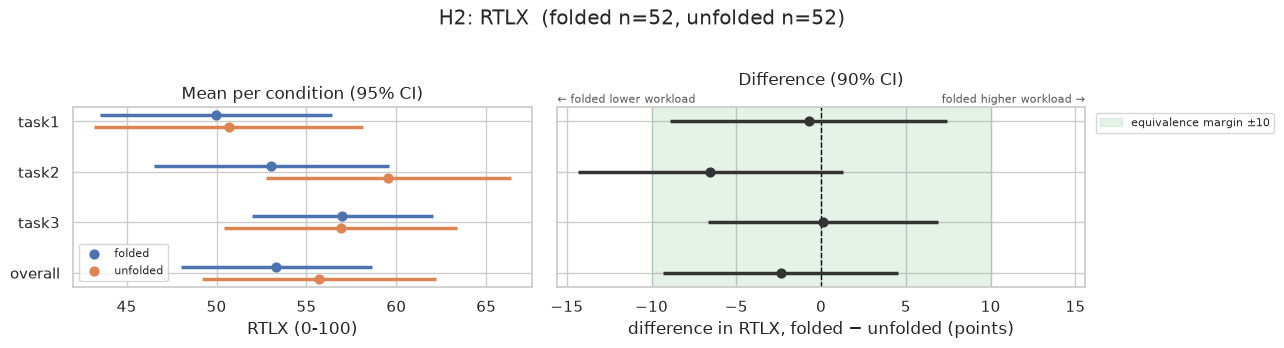

In [8]:
h2 = results[results["dv"] == "rtlx"]
r = h2[h2["role"] == "primary"].iloc[0]
print(f"Overall: diff = {r['diff']:+.1f} pts, 90% CI [{r['ci90_lo']:+.1f}, {r['ci90_hi']:+.1f}], "
      f"TOST p = {r['p']:.3f} -> {r['verdict']}")
print(f"  one-sided tests: t({r['df_tost']:.1f}) = {r['t_lower']:.2f}, p = {r['p_lower']:.3f} (above -margin); "
      f"t({r['df_tost']:.1f}) = {r['t_upper']:.2f}, p = {r['p_upper']:.3f} (below +margin)")
print(f"  difference test: Welch p = {r['p_welch']:.3f}, Hedges' g = {r['hedges_g']:.2f}")
print(f"  equivalent for any margin of ±{r['min_equiv_margin']:.1f} points or wider")
ci_plot(h2, "diff", "ci90_lo", "ci90_hi", "H2: RTLX", "difference in RTLX, folded − unfolded (points)",
        MARGINS["rtlx"], left="folded lower workload", right="folded higher workload",
        dv="rtlx", value_label="RTLX (0-100)", name="h2_rtlx")

**Per task.** RTLX after each task block, with the same columns as for H1.

In [9]:
per_task_h2 = h2.assign(
    t_CI90=h2.apply(lambda r: f"[{r['ci90_lo']:+.1f}, {r['ci90_hi']:+.1f}]", axis=1),
    bootstrap_CI90=h2.apply(lambda r: f"[{r['boot_ci90_lo']:+.1f}, {r['boot_ci90_hi']:+.1f}]", axis=1),
    p_TOST=h2["p_holm"], p_difference=h2["p_welch"],
)[["task", "mean_folded", "mean_unfolded", "diff", "t_CI90", "bootstrap_CI90", "p_TOST", "p_difference", "verdict"]]
per_task_h2.set_index("task")

,mean_folded,mean_unfolded,diff,t_CI90,bootstrap_CI90,p_TOST,p_difference,verdict
task,,,,,,,,
task1,49.95,50.67,-0.72,"[-8.9, +7.5]","[-8.8, +7.4]",0.06,0.88,inconclusive
task2,53.03,59.56,-6.53,"[-14.3, +1.3]","[-14.0, +0.9]",0.23,0.17,inconclusive
task3,57.00,56.90,0.10,"[-6.7, +6.9]","[-6.7, +6.9]",0.03,0.98,equivalent
overall,53.33,55.71,-2.39,"[-9.3, +4.6]","[-9.1, +4.4]",0.04,0.57,equivalent


**NASA-TLX subscales.** Descriptive only, no tests: each of the six subscales by task and
condition, and their mean over all tasks. RTLX is the mean of these six.

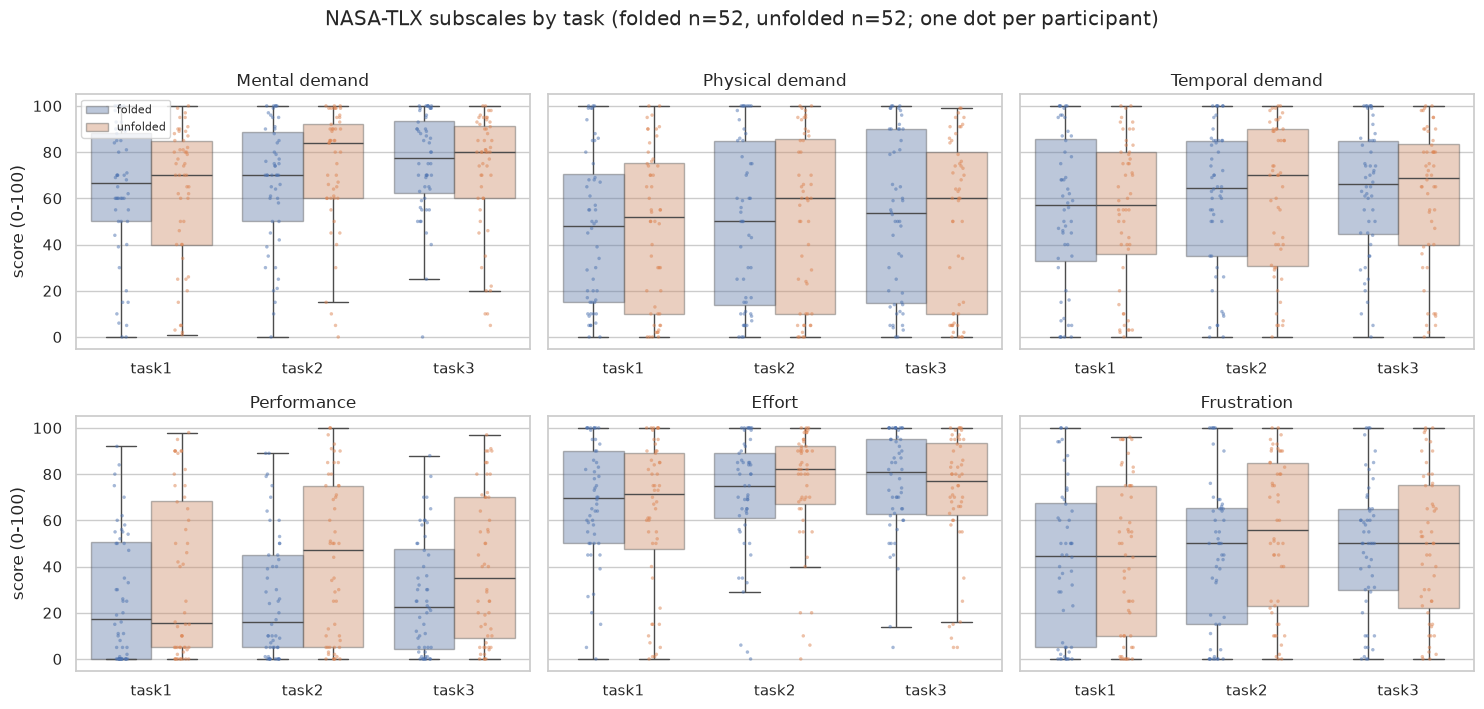

condition,folded,unfolded,diff
responseId,,,
Mental demand,68.1,68.6,-0.5
Physical demand,49.3,50.0,-0.7
Temporal demand,59.0,58.4,0.6
Performance,26.8,39.4,-12.6
Effort,71.4,69.2,2.3
Frustration,45.2,48.8,-3.5


In [10]:
SUBSCALE_TITLES = {"mental-demand": "Mental demand", "physical-demand": "Physical demand",
                   "temporal-demand": "Temporal demand", "performance": "Performance",
                   "effort": "Effort", "frustration": "Frustration"}
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, sub in zip(axes.flat, bs.NASA_SUBSCALES):
    d = tlx[tlx["responseId"] == sub]
    sns.boxplot(data=d, x="task", y="score", hue="condition", palette=COND_PALETTE, hue_order=list(COND_PALETTE),
                order=bs.TASKS, showfliers=False, boxprops={"alpha": .4}, ax=ax, legend=ax is axes.flat[0])
    sns.stripplot(data=d, x="task", y="score", hue="condition", palette=COND_PALETTE, hue_order=list(COND_PALETTE),
                  order=bs.TASKS, dodge=True, legend=False, size=2.5, alpha=.5, ax=ax)
    ax.set(title=SUBSCALE_TITLES[sub], xlabel="", ylabel="score (0-100)")
axes.flat[0].legend(title=None, loc="upper left", fontsize=8)
fig.suptitle(f"NASA-TLX subscales by task ({N_TEXT}; one dot per participant)", y=1.01)
plt.tight_layout()
show("h2_tlx_subscales")

(tlx.groupby(["responseId", "condition"])["score"].mean().unstack()
 .reindex(bs.NASA_SUBSCALES).rename(index=SUBSCALE_TITLES)
 .assign(diff=lambda t: t["folded"] - t["unfolded"]).round(1))

### H3 — Response time on T2 (common neighbors)

One-sided Mann-Whitney U test of whether folded participants are faster on T2. Reports the medians,
the typical time difference (Hodges-Lehmann shift; negative = folded faster) with a 95% CI, and the
rank-biserial effect size r.
The effect size is also given as the share of folded–unfolded pairs in which the folded participant
was faster. Two robustness checks repeat the test as a Welch t-test on log response times, and without
the slow-trial removal.


Task 2 (common neighbors): median 44.6 s folded vs 59.8 s unfolded
  difference (folded − unfolded) = -12.7 s, 95% CI [-23.7, -1.2] s, r = -0.25
  U = 1015, one-sided p = 0.014 -> supported: folded faster
  folded faster than unfolded in 62% of folded-unfolded pairs
  robustness: Welch t-test on log RT p = 0.022; without slow-trial removal p = 0.012


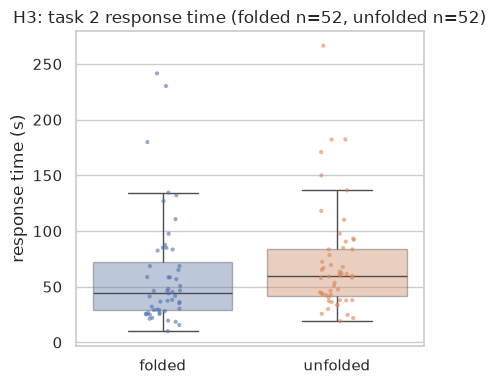

In [11]:
h3 = results[results["dv"] == "rt"].copy()
for col in ["median_folded", "median_unfolded", "hl_shift", "hl_ci95_lo", "hl_ci95_hi"]:
    h3[col] = h3[col] / 1000

r = h3[h3["role"] == "primary"].iloc[0]
print(f"Task 2 (common neighbors): median {r['median_folded']:.1f} s folded vs {r['median_unfolded']:.1f} s unfolded")
print(f"  difference (folded − unfolded) = {r['hl_shift']:+.1f} s, 95% CI [{r['hl_ci95_lo']:.1f}, {r['hl_ci95_hi']:.1f}] s, "
      f"r = {r['rank_biserial']:+.2f}")
print(f"  U = {r['U']:.0f}, one-sided p = {r['p']:.3f} -> "
      f"{'supported: folded faster' if r['significant'] else 'not supported'}")

print(f"  folded faster than unfolded in {(1 - r['rank_biserial']) / 2:.0%} of folded-unfolded pairs")

# robustness: Welch t-test on log response times, and the same test without the trial-level outlier removal
a_raw, b_raw = bs.split(bs.build_dvs(trials_raw[trials_raw["participantId"].isin(trials["participantId"])], tlx),
                        "rt", "task2")
p_untrimmed = stats.mannwhitneyu(a_raw, b_raw, alternative="less").pvalue
print(f"  robustness: Welch t-test on log RT p = {r['p_welch_log']:.3f}; "
      f"without slow-trial removal p = {p_untrimmed:.3f}")

d = plot_df[(plot_df["dv"] == "rt") & (plot_df["task"] == "task2")]
fig, ax = plt.subplots(figsize=(4.5, 4))
sns.boxplot(data=d, x="condition", y="value", hue="condition", palette=COND_PALETTE, order=list(COND_PALETTE),
            showfliers=False, boxprops={"alpha": .4}, ax=ax)
sns.stripplot(data=d, x="condition", y="value", hue="condition", palette=COND_PALETTE, order=list(COND_PALETTE),
              size=3, alpha=.6, ax=ax)
ax.set(title=f"H3: task 2 response time ({N_TEXT})", xlabel="", ylabel="response time (s)")
plt.tight_layout()
show("h3_task2_response_time")

**All tasks.** The same comparison for T1, T3 and overall: exploratory, two-sided and
Holm-corrected. The box plots show the response times per task.


,test,median_folded,median_unfolded,shift_s,CI95_s,rank_biserial,p_value,outcome
task,,,,,,,,
task1,two-sided (exploratory),29.59,32.91,-2.09,"[-8.6, +4.5]",-0.07,1.00,no difference detected
task2,one-sided (H3),44.63,59.79,-12.70,"[-23.7, -1.2]",-0.25,0.01,folded faster
task3,two-sided (exploratory),45.96,39.47,7.29,"[-2.4, +15.3]",0.16,0.46,no difference detected
overall,two-sided (exploratory),44.69,45.78,-1.24,"[-9.8, +6.4]",-0.04,1.00,no difference detected


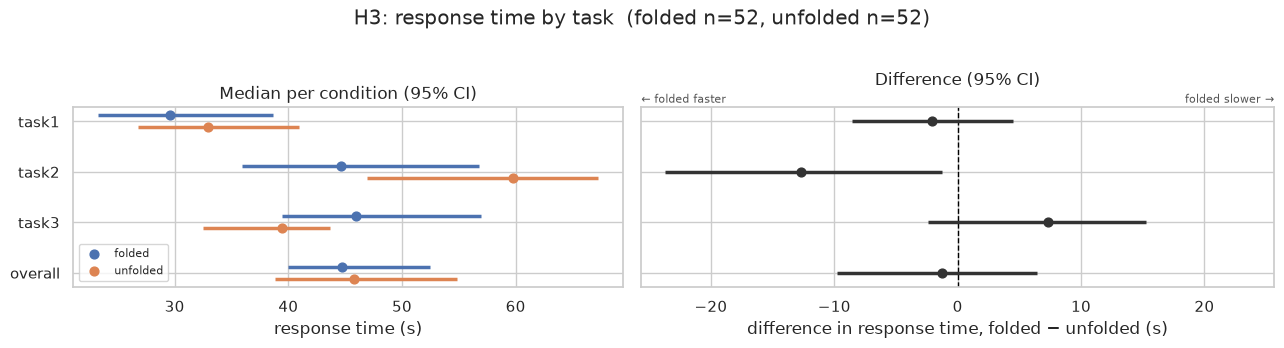

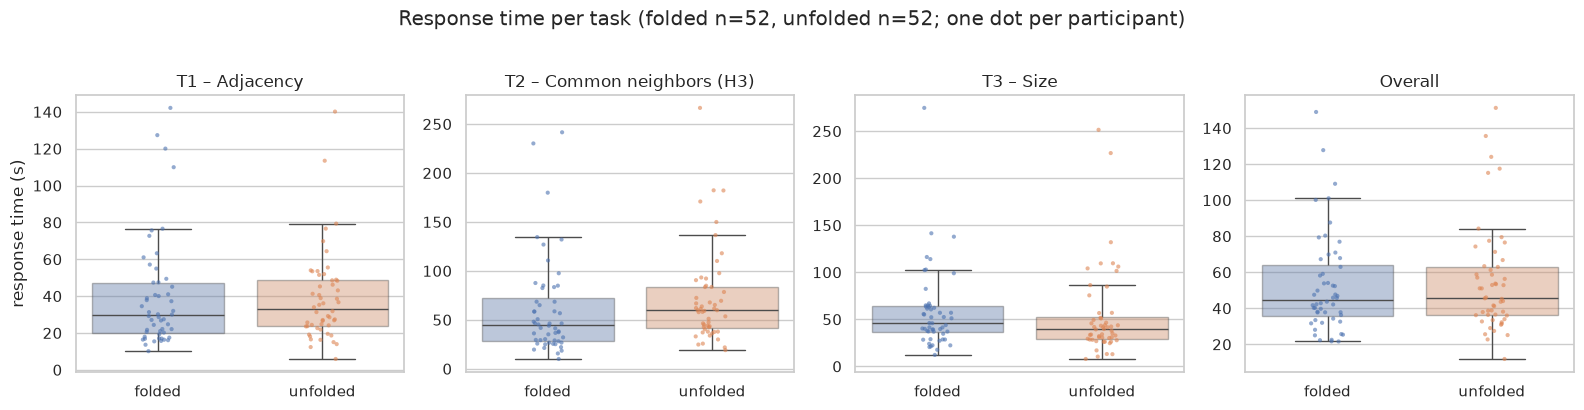

In [12]:
h3_table = h3.assign(
    test=np.where(h3["role"] == "primary", "one-sided (H3)", "two-sided (exploratory)"),
    shift_s=h3["hl_shift"],
    CI95_s=h3.apply(lambda r: f"[{r['hl_ci95_lo']:+.1f}, {r['hl_ci95_hi']:+.1f}]", axis=1),
    p_value=h3["p_holm"],
    outcome=[("folded faster" if sig else "not supported") if role == "primary"
             else ("different" if sig else "no difference detected")
             for role, sig in zip(h3["role"], h3["significant"])],
)[["task", "test", "median_folded", "median_unfolded", "shift_s", "CI95_s", "rank_biserial", "p_value", "outcome"]]
display(h3_table.set_index("task"))

ci_plot(h3, "hl_shift", "hl_ci95_lo", "hl_ci95_hi", "H3: response time by task",
        "difference in response time, folded − unfolded (s)", left="folded faster", right="folded slower",
        dv="rt", value_label="response time (s)", center="median", scale=1000, ci_label="95% CI",
        name="h3_response_time_by_task")

# response time per task and pooled, one dot per participant
TASK_LABELS = {"task1": "T1 – Adjacency", "task2": "T2 – Common neighbors (H3)", "task3": "T3 – Size", "overall": "Overall"}
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, task in zip(axes, bs.TASK_ORDER):
    d = plot_df[(plot_df["dv"] == "rt") & (plot_df["task"] == task)]
    sns.boxplot(data=d, x="condition", y="value", hue="condition", palette=COND_PALETTE, order=list(COND_PALETTE),
                showfliers=False, boxprops={"alpha": .4}, ax=ax)
    sns.stripplot(data=d, x="condition", y="value", hue="condition", palette=COND_PALETTE, order=list(COND_PALETTE),
                  size=3, alpha=.6, ax=ax)
    ax.set(title=TASK_LABELS[task], xlabel="", ylabel="response time (s)" if ax is axes[0] else "")
fig.suptitle(f"Response time per task ({N_TEXT}; one dot per participant)", y=1.02)
plt.tight_layout()
show("h3_response_time_boxplots")


## Summary

All tests in one table, saved to `results/` together with the LaTeX table of the three primary
results. `p` is uncorrected for the primary tests and Holm-corrected for the others.

In [13]:
table = results[["hypothesis", "task", "role", "test", "p_holm", "verdict"]].copy()
is_mwu = table["test"] != "TOST"
table.loc[is_mwu, "verdict"] = np.where(results.loc[is_mwu, "significant"], "different", "no difference detected")
table.loc[(table["hypothesis"] == "H3") & (table["role"] == "primary"), "verdict"] = (
    "supported: folded faster" if results.loc[(results["hypothesis"] == "H3") & (results["role"] == "primary"),
                                                 "significant"].iloc[0] else "not supported")
display(table.rename(columns={"p_holm": "p"}).set_index(["hypothesis", "task"]))

os.makedirs("results", exist_ok=True)
results.to_csv("results/study_results.csv", index=False)
with open("results/study_results_table.tex", "w") as fh:
    fh.write(bs.latex_table(results) + "\n")
print("Saved results/study_results.csv and results/study_results_table.tex")

role            test     p  \
hypothesis task                                         
H1         task1    exploratory            TOST  0.58   
           task2    exploratory            TOST  0.58   
           task3    exploratory            TOST  0.57   
           overall      primary            TOST  0.23   
H2         task1    exploratory            TOST  0.06   
           task2    exploratory            TOST  0.23   
           task3    exploratory            TOST  0.03   
           overall      primary            TOST  0.04   
H3         task1    exploratory  Mann-Whitney U  1.00   
           task2        primary  Mann-Whitney U  0.01   
           task3    exploratory  Mann-Whitney U  0.46   
           overall  exploratory  Mann-Whitney U  1.00   

                                     verdict  
hypothesis task                               
H1         task1                inconclusive  
           task2                inconclusive  
           task3                inconclusive  
           overall              inconclusive  
H2         task1                inconclusive  
           task2                inconclusive  
           task3                  equivalent  
           overall                equivalent  
H3         task1      no difference detected  
           task2    supported: folded faster  
           task3      no difference detected  
           overall    no difference detected

Saved results/study_results.csv and results/study_results_table.tex


## Results per task

All measures for every task and pooled (`overall`): each condition's mean (SD), or median [IQR] for
response time, the difference with its CI, p and the outcome. The primary test of each hypothesis is
marked; all other rows are exploratory. Saved as `results/study_results_by_task.tex` for the paper.

In [14]:
by_task = bs.results_by_task(results, dvs)
display(by_task.assign(task=by_task["task"] + np.where(by_task["primary"], " *", ""))
        .set_index(["measure", "task"])[["folded", "unfolded", "diff", "ci_lo", "ci_hi", "p", "outcome"]]
        .round(3))

with open("results/study_results_by_task.tex", "w") as fh:
    fh.write(bs.latex_results_by_task(by_task) + "\n")
print("Saved results/study_results_by_task.tex  (* = primary test)")

folded           unfolded   diff  ci_lo  ci_hi  \
measure  task                                                                   
accuracy task1            69.2 (39.0)        73.1 (39.1)  -3.85 -16.55   8.86   
         task2            65.4 (38.5)        64.7 (40.9)   0.64 -12.29  13.57   
         task3            83.7 (23.2)        84.9 (20.5)  -1.23  -8.36   5.90   
         overall *        72.8 (22.9)        74.3 (25.7)  -1.48  -9.41   6.46   
rtlx     task1            50.0 (23.2)        50.7 (26.9)  -0.72  -8.90   7.46   
         task2            53.0 (23.5)        59.6 (24.4)  -6.53 -14.33   1.27   
         task3            57.0 (18.0)        56.9 (23.3)   0.10  -6.70   6.89   
         overall *        53.3 (19.0)        55.7 (23.4)  -2.39  -9.32   4.55   
rt       task1      29.6 [20.0, 47.4]  32.9 [23.7, 48.7]  -2.09  -8.59   4.50   
         task2 *    44.6 [28.8, 72.0]  59.8 [41.9, 83.9] -12.70 -23.69  -1.24   
         task3      46.0 [36.3, 63.7]  39.5 [29.2, 52.9]   7.29  -2.41  15.26   
         overall    44.7 [35.8, 64.0]  45.8 [36.1, 63.1]  -1.24  -9.78   6.42   

                       p        outcome  
measure  task                            
accuracy task1      0.58   inconclusive  
         task2      0.58   inconclusive  
         task3      0.57   inconclusive  
         overall *  0.23   inconclusive  
rtlx     task1      0.06   inconclusive  
         task2      0.23   inconclusive  
         task3      0.03     equivalent  
         overall *  0.04     equivalent  
rt       task1      1.00  no difference  
         task2 *    0.01  folded faster  
         task3      0.46  no difference  
         overall    1.00  no difference

Saved results/study_results_by_task.tex  (* = primary test)


## How to read the results

- **H1, H2 (equivalence):** *equivalent* means the whole CI lies within the margin; *inconclusive*
  means no difference was found, but the CI extends beyond the margin.
- **H3:** *supported* if the one-sided p < .05; the shift and its CI show how much faster folding was.
- **A non-significant difference does not show equivalence;** only TOST can.
- **All other results are exploratory:** only the primary test decides a hypothesis. Judge them by their
  Holm-corrected p, not by the figures, whose CIs are uncorrected.